In [0]:
from pyspark.sql import functions as F

df = spark.table("era5_project.silver.era5_clean").select(
    "valid_time",
    "geopotential_height_m",
    "temperature_c",
    "relative_humidity",
    "pressure_level"
)

current_df = df.withColumn(
    "target_time",
    F.expr("valid_time + INTERVAL 24 HOURS")
)

future_df = df.select(
    F.col("valid_time").alias("future_time"),
    F.col("pressure_level").alias("future_pressure_level"),
    F.col("temperature_c").alias("target_temperature_c")
)

ml_df = (
    current_df.join(
        future_df,
        (current_df["target_time"] == future_df["future_time"]) &
        (current_df["pressure_level"] == future_df["future_pressure_level"]),
        "inner"
    )
    .select(
        current_df["valid_time"],
        current_df["target_time"],
        current_df["geopotential_height_m"],
        current_df["temperature_c"],
        current_df["relative_humidity"],
        current_df["pressure_level"],
        future_df["target_temperature_c"]
    )
)

print("Rows available for ML:", ml_df.count())
display(ml_df.limit(10))

Rows available for ML: 507936


valid_time,target_time,geopotential_height_m,temperature_c,relative_humidity,pressure_level,target_temperature_c
2000-01-01T12:00:00.000Z,2000-01-02T12:00:00.000Z,3045.4422254286633,1.530020000000036,36.79726,700,3.231840000000034
2000-01-01T12:00:00.000Z,2000-01-02T12:00:00.000Z,9377.137962505036,-39.46568999999997,14.784679,300,-38.47934999999998
2000-01-01T12:00:00.000Z,2000-01-02T12:00:00.000Z,13928.55256382149,-56.38636999999997,4.848752,150,-57.810479999999984
2000-01-02T12:00:00.000Z,2000-01-03T12:00:00.000Z,70.53859370937069,16.309600000000046,88.86223,1000,15.436360000000036
2000-01-02T12:00:00.000Z,2000-01-03T12:00:00.000Z,728.6095455634697,11.36474000000004,89.19455,925,9.379750000000001
2000-01-02T18:00:00.000Z,2000-01-03T18:00:00.000Z,16388.19678483478,-63.60759999999999,6.1574097,100,-61.69456999999997
2000-01-03T18:00:00.000Z,2000-01-04T18:00:00.000Z,13802.502383586649,-52.89236999999997,2.1437387,150,-56.545229999999975
2000-01-04T06:00:00.000Z,2000-01-05T06:00:00.000Z,2975.2136560395243,-2.9251499999999737,37.93555,700,2.036580000000015
2000-01-04T12:00:00.000Z,2000-01-05T12:00:00.000Z,16362.748747023705,-63.30854999999997,6.189025,100,-63.72786999999997
2000-01-05T00:00:00.000Z,2000-01-06T00:00:00.000Z,10541.838956218486,-51.362419999999986,37.95856,250,-51.65229999999997


In [0]:
from pyspark.sql import functions as F

# Find the time range
time_range = ml_df.agg(
    F.min("valid_time").alias("min_time"),
    F.max("valid_time").alias("max_time")
).first()

min_time = time_range["min_time"]
max_time = time_range["max_time"]

# Use the first 80% of the time range for training
from datetime import timedelta

cutoff_time = min_time + timedelta(
    seconds=(max_time - min_time).total_seconds() * 0.8
)

# Keep training labels before the cutoff
train_raw = ml_df.filter(
    F.col("target_time") < F.lit(cutoff_time)
)

# Keep test observations from the cutoff onward
test_raw = ml_df.filter(
    F.col("valid_time") >= F.lit(cutoff_time)
)

print("Start time:", min_time)
print("End time:", max_time)
print("Cutoff time:", cutoff_time)
print("Training rows:", train_raw.count())
print("Testing rows:", test_raw.count())

Start time: 2000-01-01 00:00:00
End time: 2026-09-28 18:00:00
Cutoff time: 2021-05-24 04:48:00
Training rows: 406289
Testing rows: 101595


In [0]:
from pyspark.sql import functions as F

# Calculate classification thresholds from training data only
thresholds = (
    train_raw
    .groupBy("pressure_level")
    .agg(
        F.expr(
            "percentile_approx(target_temperature_c, 0.33)"
        ).alias("low_threshold"),
        F.expr(
            "percentile_approx(target_temperature_c, 0.67)"
        ).alias("high_threshold")
    )
)

display(thresholds.orderBy("pressure_level"))

pressure_level,low_threshold,high_threshold
50,-60.60725999999997,-57.60630999999998
100,-63.644799999999975,-58.66973999999999
150,-58.84732999999997,-54.60356999999999
200,-56.34394999999998,-51.50160999999997
250,-52.17457999999996,-48.267259999999965
300,-45.597339999999974,-40.99363999999997
400,-31.29509999999999,-25.85594999999998
500,-19.312769999999972,-14.151700000000005
600,-9.89749999999998,-5.053380000000004
700,-2.630799999999965,1.8804600000000278


In [0]:
from pyspark.sql import functions as F

# Join the same training-derived thresholds to both datasets
train_class = train_raw.join(
    thresholds,
    on="pressure_level",
    how="left"
)

test_class = test_raw.join(
    thresholds,
    on="pressure_level",
    how="left"
)

# Create classification labels
def add_temperature_label(df):
    return df.withColumn(
        "temperature_label",
        F.when(
            F.col("target_temperature_c") <= F.col("low_threshold"),
            "Low"
        ).when(
            F.col("target_temperature_c") <= F.col("high_threshold"),
            "Medium"
        ).otherwise("High")
    )

train_class = add_temperature_label(train_class)
test_class = add_temperature_label(test_class)

# Inspect the results
display(
    train_class.select(
        "valid_time",
        "target_time",
        "pressure_level",
        "target_temperature_c",
        "temperature_label"
    )
)

valid_time,target_time,pressure_level,target_temperature_c,temperature_label
2000-06-19T18:00:00.000Z,2000-06-20T18:00:00.000Z,300,-44.469179999999966,Medium
2000-09-10T12:00:00.000Z,2000-09-11T12:00:00.000Z,300,-46.08621999999997,Low
2001-02-09T06:00:00.000Z,2001-02-10T06:00:00.000Z,300,-29.84964999999997,High
2001-02-28T18:00:00.000Z,2001-03-01T18:00:00.000Z,300,-39.12587999999997,High
2001-07-07T12:00:00.000Z,2001-07-08T12:00:00.000Z,300,-45.86734999999999,Low
2000-07-24T06:00:00.000Z,2000-07-25T06:00:00.000Z,300,-49.318929999999966,Low
2000-01-16T00:00:00.000Z,2000-01-17T00:00:00.000Z,300,-42.04048999999998,Medium
2000-05-14T06:00:00.000Z,2000-05-15T06:00:00.000Z,300,-38.117879999999985,High
2001-01-28T12:00:00.000Z,2001-01-29T12:00:00.000Z,300,-39.02926999999997,High
2001-06-06T06:00:00.000Z,2001-06-07T06:00:00.000Z,300,-50.41963999999999,Low


In [0]:
display(
    train_class
    .groupBy("temperature_label")
    .count()
    .orderBy("temperature_label")
)

temperature_label,count
High,134090
Low,134063
Medium,138136


In [0]:
from pyspark.ml.feature import StringIndexer, VectorAssembler

# Convert class labels into numeric labels
label_indexer = StringIndexer(
    inputCol="temperature_label",
    outputCol="label",
    stringOrderType="alphabetAsc"
)

label_model = label_indexer.fit(train_class)

train_indexed = label_model.transform(train_class)
test_indexed = label_model.transform(test_class)

# Combine input features into a feature vector
feature_cols = [
    "temperature_c",
    "relative_humidity",
    "geopotential_height_m",
    "pressure_level"
]

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)

train_ml = assembler.transform(train_indexed).select(
    "valid_time",
    "target_time",
    "pressure_level",
    "temperature_label",
    "label",
    "features"
)

test_ml = assembler.transform(test_indexed).select(
    "valid_time",
    "target_time",
    "pressure_level",
    "temperature_label",
    "label",
    "features"
)

display(train_ml.limit(10))

valid_time,target_time,pressure_level,temperature_label,label,features
2001-12-26T12:00:00.000Z,2001-12-27T12:00:00.000Z,300,High,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-37.56019999999998"",""101.9946"",""9375.94642411017"",""300.0""]}"
2001-01-04T18:00:00.000Z,2001-01-05T18:00:00.000Z,700,Medium,2.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""2.2446500000000356"",""12.8587055"",""3156.4152896248975"",""700.0""]}"
2001-07-13T12:00:00.000Z,2001-07-14T12:00:00.000Z,50,High,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-58.45474999999999"",""1.4456176"",""20477.794149888086"",""50.0""]}"
2001-09-30T06:00:00.000Z,2001-10-01T06:00:00.000Z,850,Medium,2.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""4.935270000000003"",""78.63851"",""1599.4292648355963"",""850.0""]}"
2002-04-01T06:00:00.000Z,2002-04-02T06:00:00.000Z,850,Low,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""2.6736000000000217"",""45.76049"",""1414.5567038693132"",""850.0""]}"
2000-08-07T18:00:00.000Z,2000-08-08T18:00:00.000Z,925,Low,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""4.148800000000051"",""75.13922"",""892.3384642054117"",""925.0""]}"
2001-08-18T18:00:00.000Z,2001-08-19T18:00:00.000Z,925,Low,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""7.618070000000046"",""79.35598"",""671.8945817379024"",""925.0""]}"
2000-04-25T18:00:00.000Z,2000-04-26T18:00:00.000Z,100,Medium,2.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-58.81335999999999"",""3.1007595"",""16113.147710992032"",""100.0""]}"
2000-05-12T12:00:00.000Z,2000-05-13T12:00:00.000Z,150,Medium,2.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-55.63769999999997"",""5.0496807"",""13837.364441475938"",""150.0""]}"
2001-04-29T18:00:00.000Z,2001-04-30T18:00:00.000Z,150,Low,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-61.36540999999997"",""8.71441"",""13850.436183610103"",""150.0""]}"


In [0]:
from pyspark.ml.classification import RandomForestClassifier

rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    predictionCol="prediction",
    numTrees=100,
    maxDepth=10,
    minInstancesPerNode=100,
    seed=42
)

rf_model = rf.fit(train_ml)

predictions_rf = rf_model.transform(test_ml)

display(
    predictions_rf.select(
        "valid_time",
        "target_time",
        "pressure_level",
        "temperature_label",
        "label",
        "prediction",
        "probability"
    )
)

valid_time,target_time,pressure_level,temperature_label,label,prediction,probability
2021-05-24T18:00:00.000Z,2021-05-25T18:00:00.000Z,1000,Low,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.026419167025263982"",""0.7494496179886763"",""0.2241312149860598""]}"
2021-05-25T00:00:00.000Z,2021-05-26T00:00:00.000Z,925,Low,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.14374830716565373"",""0.51093974237921"",""0.3453119504551363""]}"
2021-05-26T18:00:00.000Z,2021-05-27T18:00:00.000Z,50,High,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.6333030754572031"",""0.01898770358057207"",""0.34770922096222473""]}"
2021-05-27T00:00:00.000Z,2021-05-28T00:00:00.000Z,700,Low,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.23057652272370405"",""0.38992969118532983"",""0.3794937860909661""]}"
2021-05-28T06:00:00.000Z,2021-05-29T06:00:00.000Z,150,High,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.7739258737529605"",""0.03405366673073817"",""0.1920204595163013""]}"
2021-05-29T18:00:00.000Z,2021-05-30T18:00:00.000Z,925,Medium,2.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.12178839262236528"",""0.4989352424336539"",""0.37927636494398087""]}"
2021-05-30T12:00:00.000Z,2021-05-31T12:00:00.000Z,700,Low,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.19790242035043587"",""0.4757872807492124"",""0.3263102989003518""]}"
2021-05-31T12:00:00.000Z,2021-06-01T12:00:00.000Z,925,Low,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.12023742166024343"",""0.5065343412592308"",""0.3732282370805259""]}"
2021-06-01T18:00:00.000Z,2021-06-02T18:00:00.000Z,100,High,0.0,2.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.3187727588380867"",""0.10841732527078468"",""0.5728099158911287""]}"
2021-06-02T12:00:00.000Z,2021-06-03T12:00:00.000Z,250,Low,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.14203445567602607"",""0.5813061701396419"",""0.27665937418433206""]}"


In [0]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

metric_names = [
    "accuracy",
    "weightedPrecision",
    "weightedRecall",
    "f1"
]

for metric_name in metric_names:
    evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metric_name
    )

    score = evaluator.evaluate(predictions_rf)
    print(f"{metric_name}: {score:.4f}")

accuracy: 0.6731
weightedPrecision: 0.6674
weightedRecall: 0.6731
f1: 0.6675


In [0]:
from pyspark.sql import functions as F

confusion_matrix = (
    predictions_rf
    .groupBy("label", "prediction")
    .count()
    .orderBy("label", "prediction")
)

display(confusion_matrix)

label,prediction,count
0.0,0.0,28367
0.0,1.0,1718
0.0,2.0,7001
1.0,0.0,928
1.0,1.0,23962
1.0,2.0,5606
2.0,0.0,7754
2.0,1.0,10209
2.0,2.0,16050


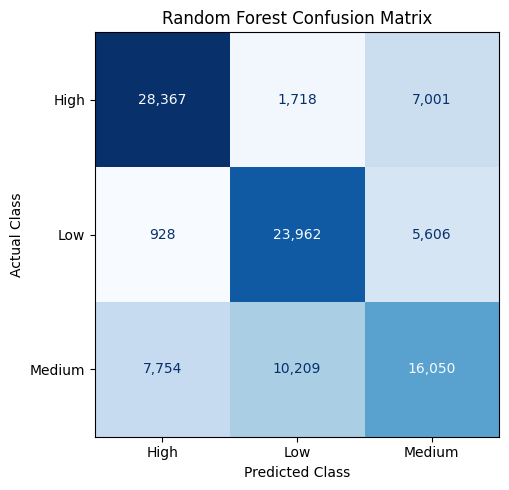

In [0]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Use Random Forest test predictions
pdf_rf = predictions_rf.select(
    "label", "prediction"
).toPandas()

# LabelIndexer uses alphabetic order:
# High = 0, Low = 1, Medium = 2
class_order = [0.0, 1.0, 2.0]
class_names = ["High", "Low", "Medium"]

cm = confusion_matrix(
    pdf_rf["label"],
    pdf_rf["prediction"],
    labels=class_order
)

fig, ax = plt.subplots(figsize=(7, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=",",
    colorbar=False
)

ax.set_title("Random Forest Confusion Matrix")
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

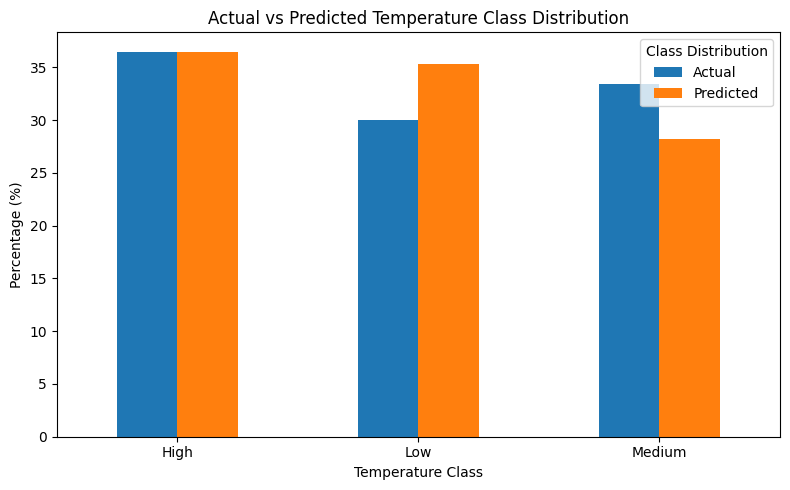

Actual,Predicted
36.5,36.47
30.02,35.33
33.48,28.21


In [0]:
import matplotlib.pyplot as plt
import pandas as pd

class_order = [0.0, 1.0, 2.0]
class_names = ["High", "Low", "Medium"]

# Actual class distribution
actual_dist = (
    pdf_rf["label"]
    .value_counts(normalize=True)
    .reindex(class_order, fill_value=0) * 100
)

# Predicted class distribution
predicted_dist = (
    pdf_rf["prediction"]
    .value_counts(normalize=True)
    .reindex(class_order, fill_value=0) * 100
)

distribution_df = pd.DataFrame({
    "Actual": actual_dist.values,
    "Predicted": predicted_dist.values
}, index=class_names)

ax = distribution_df.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

ax.set_xlabel("Temperature Class")
ax.set_ylabel("Percentage (%)")
ax.set_title("Actual vs Predicted Temperature Class Distribution")
ax.legend(title="Class Distribution")

plt.tight_layout()
plt.show()

display(distribution_df.round(2))